pion, forward_q0_0_0, fb, GEVP smear01_gamma012_t03_tref6: 183 cfgs, 7 momenta
  2pt: 2pt_reconstructed_pion_forward_q0_0_0_smear01_gamma012_t03_tref6_3072src_ncfg183.h5
  fit: twopt_fit_results_pion_forward_q0_0_0_gevp_smear01_gamma012_t03_tref6_fb_3072src_ncfg183.h5:nstate3_t5-15_svd1e-04_tref10, t = 5..15, 7 momenta
  p = (0, 0, 0): fit E0 = 0.14133(0.00026), chi2/dof = 0.29
  p = (0, 0, 1): fit E0 = 0.24181(0.00037), chi2/dof = 0.35
  p = (0, 0, 2): fit E0 = 0.41329(0.00138), chi2/dof = 0.85
  p = (0, 0, 3): fit E0 = 0.59262(0.00450), chi2/dof = 1.04
  p = (0, 0, 4): fit E0 = 0.77688(0.01071), chi2/dof = 0.59
  p = (0, 0, 5): fit E0 = 0.92082(0.02856), chi2/dof = 0.91
  p = (0, 0, 6): fit E0 = 1.15720(0.15802), chi2/dof = 0.82


/var/folders/fd/b0prbcvx72l2qq4ncklr4nq40000gn/T/ipykernel_34524/3528685263.py:129: RuntimeWarning: invalid value encountered in log
  model_mean, model_err = jk(np.log(two_point[:, :-1] / two_point[:, 1:]) / dt)


  plot: /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/forward_q0_0_0/plots/meff_pion_forward_q0_0_0_gevp_smear01_gamma012_t03_tref6_fb_nstate3_t5-15_svd1e-04_tref10_ncfg183.png


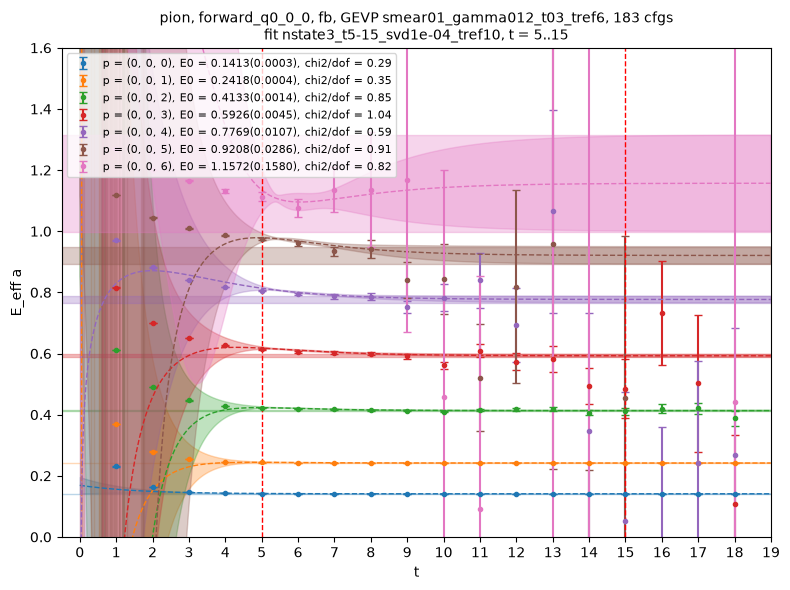

In [4]:
#Effective mass plot of the final Delta 2pt, from the files with the most cfgs, for one hadron and one direction (forward, backward or fb).
#Data points: m_eff(t) = ln C(t)/C(t+1) of the 2pt (mean over t_src) on the delete-one jackknife replicates over cfgs.
#On top, when the 2pt fit of the offforward notebook (section 4a) exists for this hadron, kinematics, basis and direction:
#  the horizontal band is E0 of the fit (jackknife), and the dashed curve with its band is the effective mass of the fitted model
#  sum_n c_n [e^{-E_n t} + e^{-E_n (Lt - t)}] on every jackknife replicate (E_jk, C_jk of the fit file), as in the old 2pt_plot_meff script.
#  The model curve is drawn only when the data are the 2pt the fit was done on (pt2_source = "gevp" with the same basis).
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt

here = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta"

hadron = "pion"                                 # "pion" or "proton"
direction = "fb"                                # "forward" C(t_src + t), "backward" C(t_src - t), or "fb" = their mean
frame, q = "forward", [0, 0, 0]                 # kinematics of the 2pt file, as in the notebook settings
pt2_source = "gevp"                             # "gevp": the reconstructed 2pt of the notebook (section 1); "single": one operator of the packed 2pt file
smear_use, gamma_use, t0, t_ref = [0, 1], [0, 1, 2], 3, 6     # pt2_source "gevp": the basis of the reconstructed 2pt, as in the notebook settings
single_op = (0, 1)                              # pt2_source "single": (smear, gamma); smear 0 = [4.5, 2.25, 0.8], 1 = [1.5, 1.5, 0]; gamma 0 = G5, 1 = G5G4, 2 = G3G5
show_fit = True                                 # draw the 2pt fit of the notebook (section 4a) when its file exists
fit_tag = None                                  # group of the fit file, e.g. "nstate3_t5-15_svd1e-04_tref10"; None: the only group of the file (an error lists them if there are several)
pz_plot_list = None                             # pz = p_f[2] to plot, e.g. [0, 1, 2]; None: every momentum of the file
t_plot_max = 18                                 # last t of the data points (the files hold tsep 0..19, so m_eff(t) exists up to 18)
ylim = (0, 1.6)
Lt = 96
c_sign = {"pion": -1, "proton": +1}[hadron]     # the pion comes out negative (the fermion-loop sign is not in the code), the projected proton positive


def jk(data):
    #mean and jackknife error over axis 0 of delete-one replicates
    n = data.shape[0]
    mean = np.mean(data, axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))


def ncfg_of(name):
    return int(name.split("_ncfg")[1].split("_")[0].split(".")[0])


def newest(pattern):
    #the file of this pattern with the most cfgs
    found = glob.glob(pattern)
    assert found, f"no file {pattern}"
    return max(found, key=ncfg_of)


def text(values):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in values]


kin_tag = f"{frame}_q{q[0]}_{q[1]}_{q[2]}"
out_dir = f"{here}/final_production/{kin_tag}"
plot_dir = f"{out_dir}/plots"
pt2_tag = "smear" + "".join(str(s) for s in smear_use) + "_gamma" + "".join(str(g) for g in gamma_use) + f"_t0{t0}_tref{t_ref}"

#---- the 2pt per cfg, mean over t_src: halves[direction] = (cfg, pz, tsep), real, positive at small t
if pt2_source == "gevp":
    pt2_file = newest(f"{out_dir}/2pt_reconstructed_{hadron}_{kin_tag}_{pt2_tag}_*src_ncfg*.h5")
    with h5py.File(pt2_file, "r") as f:
        pf_list = f["pf_list"][:]
        cfg_list = f["cfg_list"][:]
        halves = {d: f[f"pt2_C2pf_{d}"][:].mean(axis=1).real for d in ("forward", "backward")}      # c_sign is already in the file
    data_tag, data_label = f"gevp_{pt2_tag}", f"GEVP {pt2_tag}"
else:
    role = "C3input" if frame == "forward" else "C2pf"                                               # at q = 0 the C3input file is also the C2pf file
    pt2_file = newest(f"{here}/2pt_*_GEVP_{kin_tag}_{role}_*_ncfg*_{hadron}{'_projected' if hadron == 'proton' else ''}.h5")
    s, g = single_op
    with h5py.File(pt2_file, "r") as f:
        pf_list = f["pf_list"][:]
        cfg_list = f["cfg_list"][:]
        smear_names, gamma_list = text(f["smear_names"][:]), text(f.attrs["gamma_list"])
        halves = {d: c_sign * f[f"pt2_{d}"][:, s, s, g, g].mean(axis=1).real for d in ("forward", "backward")}   # (cfg, t_src, pz, tsep) -> mean over t_src
    data_tag, data_label = f"single_{smear_names[s]}_{gamma_list[g]}", f"{smear_names[s]} {gamma_list[g]}"
C = halves[direction] if direction != "fb" else 0.5 * (halves["forward"] + halves["backward"])
n_cfg = len(cfg_list)
t_first = 1 if hadron == "proton" and direction != "forward" else 0     # the proton's backward tsep = 0 is the source slice projected with parity_m: not usable
print(f"{hadron}, {kin_tag}, {direction}, {data_label}: {n_cfg} cfgs, {len(pf_list)} momenta")
print(f"  2pt: {os.path.basename(pt2_file)}")

#---- the data effective mass on the jackknife replicates: (jk, pz, t), t = 0 .. tsep_max - 2
with np.errstate(invalid="ignore", divide="ignore"):
    C_jk = (C.sum(axis=0)[None] - C) / (n_cfg - 1)
    meff_jk = np.log(C_jk[:, :, :-1] / C_jk[:, :, 1:])
meff_mean, meff_err = jk(meff_jk)

#---- the 2pt fit of the notebook (section 4a) of this hadron, kinematics, basis and direction: per momentum E_jk, C_jk (jk, state) and chi2/dof
fit = {}
fit_of_this_data = False
if show_fit:
    found = glob.glob(f"{out_dir}/twopt_fit_results_{hadron}_{kin_tag}_gevp_{pt2_tag}_{direction}_*src_ncfg*.h5")
    if not found:
        print(f"  no 2pt fit of {hadron} {kin_tag} gevp {pt2_tag} direction {direction} in {out_dir}: run section 4a of the notebook with DIRECTION = '{direction}'; data only")
    else:
        fit_file = max(found, key=ncfg_of)
        with h5py.File(fit_file, "r") as f:
            if fit_tag is None and len(f) == 1:
                fit_tag = list(f)[0]
            assert fit_tag in f, f"{os.path.basename(fit_file)}: set fit_tag to one of {list(f)}"
            group = f[fit_tag]
            assert int(group.attrs["n_jk"]) == n_cfg, f"the fit has {group.attrs['n_jk']} jackknife samples, the data {n_cfg} cfgs"
            fit_window = (int(group.attrs["tmin"]), int(group.attrs["tmax"]))
            fit_of_this_data = pt2_source == "gevp" and os.path.basename(str(group.attrs["pt2_source"])) == os.path.basename(pt2_file)
            for name in group:
                fit[name] = {"E_jk": group[name]["E_jk"][:], "C_jk": group[name]["C_jk"][:], "chi2dof": float(group[name]["chi2dof_central"][()])}
        print(f"  fit: {os.path.basename(fit_file)}:{fit_tag}, t = {fit_window[0]}..{fit_window[1]}, {len(fit)} momenta"
              + ("" if fit_of_this_data else "; it is a fit of the GEVP 2pt, not of these data: only its E0 is drawn"))

#---- the plot: one axes, one color per momentum
plt.figure(figsize=(8, 6))
t_data = np.arange(t_first, t_plot_max + 1)
t_span = np.linspace(0, t_plot_max + 1, 2000)
dt = t_span[1] - t_span[0]
for ip, pf in enumerate(pf_list):
    if pz_plot_list is not None and int(pf[2]) not in pz_plot_list:
        continue
    color = f"C{ip}"
    label = f"p = {tuple(int(v) for v in pf)}"
    mom_name = f"p{pf[0]}_{pf[1]}_{pf[2]}"
    if mom_name in fit:
        E_jk, C_jk_fit, chi2dof = fit[mom_name]["E_jk"], fit[mom_name]["C_jk"], fit[mom_name]["chi2dof"]
        E0_mean, E0_err = jk(E_jk[:, 0])
        print(f"  p = {tuple(int(v) for v in pf)}: fit E0 = {E0_mean:.5f}({E0_err:.5f}), chi2/dof = {chi2dof:.2f}")
        plt.axhspan(E0_mean - E0_err, E0_mean + E0_err, color=color, alpha=0.3)
        label += f", E0 = {E0_mean:.4f}({E0_err:.4f}), chi2/dof = {chi2dof:.2f}"
        if fit_of_this_data:
            #the fitted model on every jackknife replicate: two_point (jk, t) = sum_n c_n [e^{-E_n t} + e^{-E_n (Lt - t)}], then m_eff = ln[C(t)/C(t+dt)]/dt
            two_point = np.sum(C_jk_fit[:, :, None] * (np.exp(-E_jk[:, :, None] * t_span) + np.exp(-E_jk[:, :, None] * (Lt - t_span))), axis=1)
            model_mean, model_err = jk(np.log(two_point[:, :-1] / two_point[:, 1:]) / dt)
            plt.plot(t_span[:-1], model_mean, ls="dashed", lw=1, color=color)
            plt.fill_between(t_span[:-1], model_mean - model_err, model_mean + model_err, alpha=0.3, color=color)
    plt.errorbar(t_data, meff_mean[ip, t_first:t_plot_max + 1], meff_err[ip, t_first:t_plot_max + 1], fmt="o", ms=3, color=color, capsize=3, label=label)

title = f"{hadron}, {kin_tag}, {direction}, {data_label}, {n_cfg} cfgs"
if fit:
    plt.axvline(x=fit_window[0], color="red", linestyle="--", linewidth=1)
    plt.axvline(x=fit_window[1], color="red", linestyle="--", linewidth=1)
    title += f"\nfit {fit_tag}, t = {fit_window[0]}..{fit_window[1]}" + ("" if fit_of_this_data else " (E0 only)")
plt.title(title, fontsize=10)
plt.xlabel("t")
plt.ylabel("E_eff a")
plt.xticks(np.arange(t_plot_max + 2))
plt.xlim(-0.5, t_plot_max + 1)
plt.ylim(*ylim)
plt.legend(fontsize=8)
plt.tight_layout()
os.makedirs(plot_dir, exist_ok=True)
plot_path = f"{plot_dir}/meff_{hadron}_{kin_tag}_{data_tag}_{direction}{'_' + fit_tag if fit else ''}_ncfg{n_cfg}.png"
plt.savefig(plot_path, dpi=150)
print(f"  plot: {plot_path}")
plt.show()